In [58]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/CleanedLifeInsurance.csv")

In [59]:
# Create new dataframe with just "ENTRY AGE" and "POLICY STATUS"
df = df[["ENTRY AGE", "is_lapse"]].copy()
print(df.head())

   ENTRY AGE  is_lapse
0         36         0
1         42         0
2         40         1
3         39         1
4         44         1


In [60]:
bins = [0, 18, 26, 36, 50, 65, float("inf")]
labels = ["0-17", "18-25", "26-35", "36-49", "50-64", "65+"]

df["age_bucket"] = pd.cut(df["ENTRY AGE"], bins=bins, labels=labels, right=False)

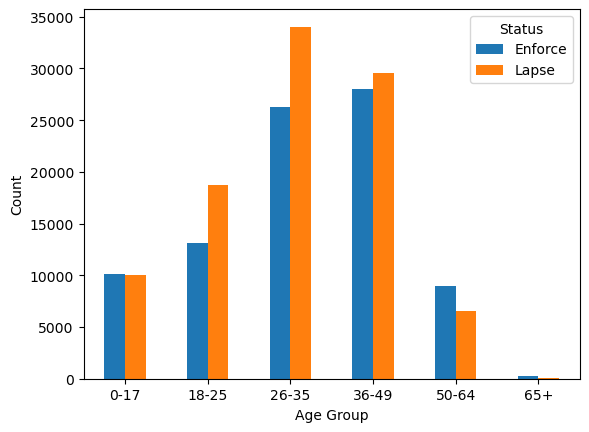

In [61]:
pd.crosstab(df["age_bucket"], df["is_lapse"]).plot(kind="bar", rot = 0)

plt.xlabel("Age Group")
plt.ylabel("Count")
plt.legend(title="Status", labels=["Enforce", "Lapse"])

plt.show()

In [62]:
# Create a new, compressed summary table
summary_df = df.groupby('age_bucket')['is_lapse'].mean().reset_index()

# Convert the fraction to a clean percentage
summary_df['lapse_percentage'] = summary_df['is_lapse'] * 100

# Drop the old 'is_lapse' column to avoid confusion
summary_df = summary_df.drop(columns=['is_lapse'])

print(summary_df)

  age_bucket  lapse_percentage
0       0-17         49.756727
1      18-25         58.817973
2      26-35         56.472892
3      36-49         51.276973
4      50-64         42.295994
5        65+         21.336761


/var/folders/s6/x4b18jbs2c34q4hjs_b8sphr0000gn/T/ipykernel_71023/861329336.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary_df = df.groupby('age_bucket')['is_lapse'].mean().reset_index()


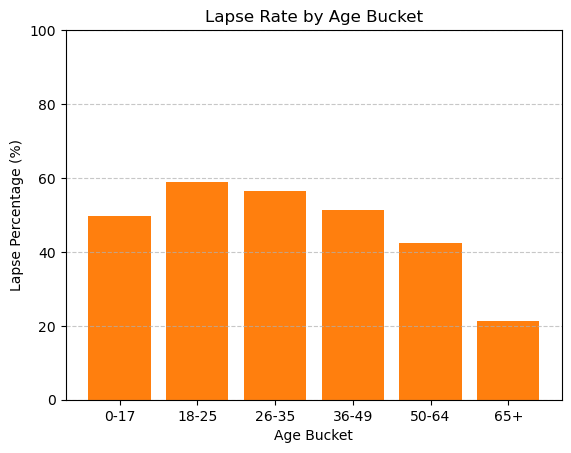

In [66]:
# 1. Plot the bars
plt.bar(summary_df['age_bucket'], summary_df['lapse_percentage'], color='#ff7f0e')

# 2. Scale the Y-axis from 0 to 100
plt.ylim(0, 100)

# 3. Add horizontal gridlines
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add basic labels
plt.ylabel('Lapse Percentage (%)')
plt.xlabel('Age Bucket')
plt.title('Lapse Rate by Age Bucket')



plt.show()
